<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/5.%20sequential%20models/5.%20LSTM_text_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Text as Sequence data for LSTM models
> (codespaces notebook)
- We can process text as sequential data and use an LSTM to predict the next letter in the sequence.
- This is the heart of most LLM's today. There are several steps that are performed on the data pre and post model transfer.
- I have explained the basic concepts of Natural Language Processing mentioned below in my [blog](https://jayadeep19.github.io/til-notes/NLP-basics)
  1. Text Processing
  2. Stemming
  3. Lemmatization
  4. POS Tagging
  5. Bag of words (Bow), TF-IDF. Text Representation
  6. Word Embeddings
  7. Seq2Seq model
  8. Attention Mechanism
- In this notebook, I will implement a text classifier wih LSTM that takes in a sequence of data and outputs a single class (Many to one just like our time series prediction).
- Also I will try to implement many of those concepts that mentioned above in pytorch.

   

## Workflow
- fisrt we will see the tokenization and how we can achieve it on a sentence
- The, we will build a vocab dict that contains all the words in the dataset.
    - This vocab object we ca use to assign a unique ID to all tokens(words) that we generated first.
    - [build_vocab_from_iterator](https://docs.pytorch.org/text/stable/vocab.html)
- We then use the vocab object to define a transform that we can apply to text and transform it to the shape and type that our model expects (we use this transform on the text just before we pass it to the model.)
    - We can also add special padding tokens for the start and end of the sentence
- The model is just an LSTM that we defined in an earlier notebook.
    - However, we add another layer at the start that **Embeds** the unique id's into ndim embeddings.
    - This ndim is a hyper parameter that we train and adjust while we train.]
    - However, we will initiate the ndim with the len of vocab (Think of it as onehot encoding, we get len(vocab) dim vector for each token Id.)
 ```mermaid
flowchart TD
    A[Raw Input Sentence] --> B[1. Tokenization<br/>Split sentence into individual words/tokens]
    B --> C[2. Build Vocabulary Dictionary<br/>Collect all unique words in dataset & assign unique IDs]
    
    C --> D[3. Define Text Transform Pipeline]
    subgraph Transform [Pre-Model Text Transform]
        direction TB
        D1[Map tokens to unique IDs via Vocab] --> D2[Add special padding tokens<br/>Start & End of sentence]
        D2 --> D3[Format to expected tensor shape & type]
    end
    
    D --> D1
    D3 --> E[4. Embedding Layer<br/>Converts unique IDs into ndim dense vectors]
    
    subgraph Hyperparams [Embedding Configuration]
        direction LR
        H1["Initial dim = len(vocab)<br/>(Similar to One-Hot Encoding)"] -.-> H2["Target dim = ndim<br/>(Tunable hyperparameter)"]
    end
    
    H2 -.-> E
    E --> F[5. LSTM Model<br/>Pre-defined architecture from earlier notebook]
    F --> G[Model Output / Predictions]
```


- Pytorch provides a dedicated library for NLP called - [`torchtext`](https://docs.pytorch.org/text/stable/index.html)
> - Important note: This Library is not continued by the pytorch team and is depreciated.
> - The last stable version of this library is [0.18.0](https://docs.pytorch.org/text/versions.html) and I am only using this library to implement
>    the concepts of NLP in PYTORCH. Normally pytorch moved its NLP pipelines to libraries like Huggingface's `tokenizers` and `transformers`

In [2]:
import torch
import torchtext
import torch.optim as optim
from torch.utils.data import DataLoader
from torch import nn

from pathlib import Path
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

## Dataset

- we can find some basic datasets from pytorch to practice our NLP skills
- we can get them from `torchtext.datasets.<name>`.
- It uses a new object called a **DataPipe**. This yeilds a tuple of label and text
- [AG_NEWS](https://docs.pytorch.org/text/0.16.0/_modules/torchtext/datasets/ag_news.html#AG_NEWS)

In [3]:
'''
We will use the AG_NEWS dataset from pytorch for text classification
It has 4 classes of news articles: World, Sports, Business, Sci/Tech.
The goal is to classify a new input sequence into these 4 categories using a trained LSTM model.
- This returns an iterable DataPipe object which is a tuple of lable and text
'''
from torchtext.datasets import AG_NEWS

data_dir = Path("../assets/datasets")

train_data = AG_NEWS(root=data_dir.parent, split='train')
test_data = AG_NEWS(root = data_dir.parent, split= 'test')
#train_data, test_data = AG_NEWS(root = './data')

In [4]:
# exploring data

for i, (label, text) in enumerate(train_data):
    if i<10:
        print(label, text, "/n")
        #print('size of label: ', label.size(), 'size of text: ', text.split())
    else:
        break

3 Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again. /n
3 Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market. /n
3 Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums. /n
3 Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the main pipeline in southern Iraq after\intelligence showed a rebel militia could strike\infrastructure, an oil official said on Saturday. /n
3 Oil prices soar to all-time record, posing new menace to US economy (AFP) AF

In [5]:
num_train = len(list(train_data))
num_test = len(list(test_data))

print(f'Number of train samples: {num_train}, Number of test samples: {num_test}')

/root/.local/lib/python3.11/site-packages/torch/utils/data/datapipes/iter/combining.py:333: UserWarning: Some child DataPipes are not exhausted when __iter__ is called. We are resetting the buffer and each child DataPipe will read from the start again.
  warnings.warn("Some child DataPipes are not exhausted when __iter__ is called. We are resetting "


Number of train samples: 120000, Number of test samples: 7600


In [6]:
LABELS = {
    1: "World",
    2: "Sports",
    3: "Business",
    4: "Sci/Tech"
}

## Tokenization

- Play with openAI [Tokenizers](https://platform.openai.com/tokenizer)
- It is the process of breaking the input sequence into small chunks and further we can convert them to unique ID's!!

- We can import the basic tokenizers from `from torchtext.data.utils import get_tokenizer`. we have the option to pass a custom function tokenizer as argument!!

- we can also import specalized tokenizers that are based on pretrained models ex: BERT tokenizer, or SentencePiece Tokenizer from `torchtext.transforms.<name>`

In [7]:
label, text = next(iter(train_data))

#A basic tokenizer that splits on whitespaces
# But we can use more advanced tokenizers from pytorch or other libraries like huggingface, spacy etc..
text.split()

['Wall',
 'St.',
 'Bears',
 'Claw',
 'Back',
 'Into',
 'the',
 'Black',
 '(Reuters)',
 'Reuters',
 '-',
 'Short-sellers,',
 'Wall',
 "Street's",
 'dwindling\\band',
 'of',
 'ultra-cynics,',
 'are',
 'seeing',
 'green',
 'again.']

In [8]:
# Example of tokenization
from torchtext.data.utils import get_tokenizer

tokenizer = get_tokenizer('basic_english')
sequence = 'Hey we are going to tokenize this sentence!'
tokens = tokenizer(sequence)

print(tokens)

['hey', 'we', 'are', 'going', 'to', 'tokenize', 'this', 'sentence', '!']


In [9]:
#we got a similar tokenization as the basic pythons split function
#But pytorchs version can handle more complex characters and punctuations..
tokenizer(text)

['wall',
 'st',
 '.',
 'bears',
 'claw',
 'back',
 'into',
 'the',
 'black',
 '(',
 'reuters',
 ')',
 'reuters',
 '-',
 'short-sellers',
 ',',
 'wall',
 'street',
 "'",
 's',
 'dwindling\\band',
 'of',
 'ultra-cynics',
 ',',
 'are',
 'seeing',
 'green',
 'again',
 '.']

In [10]:
from torchtext.vocab import build_vocab_from_iterator

# We use yield instead of return to continue the execution of function instead of stopping it
# It tokenize a sentence at a time and not the entire dataset once.

def get_tokens(data_iter):
    for label, text in data_iter:
        yield tokenizer(text)

#[build_vocab_from_iterator]
'''
We specify that we add special tokens so that our model knows when some unknown words are encountered.
<unk>: Token used to specify unknown words. (The words that are not in the vocab)
<sos>: Token specifies the start of the sentence
<eos>: Token specifies the end os sentence
<pad>: We add these tokens to make sure that all the sentences are of same length before passing to the model.
'''

vocab = build_vocab_from_iterator(
    get_tokens(train_data),
    min_freq = 2,  # the num of time a word has to be repeated to be added to tthe vocab
    specials = ['<unk>', '<sos>', '<eos>', '<pad>'],
    special_first = True  #we keep the special tokens at the start of voacb (0,1,2,3..) and not some other number.
)

#we have to set the default index to <unk>, this sets the tokens of the unknown words to <unk> token.
vocab.set_default_index(vocab['<unk>'])


In [11]:
#see the behaviour of vocab for tokens of known and unknown.
print('The index of the word "wall is: "',vocab['wall'])  # known token as seen in the tokenizer output

print('The index of a random word that is not in the vocab is : ',vocab['India'])

The index of the word "wall is: " 434
The index of a random word that is not in the vocab is :  0


In [12]:
#length of the vocabulory we built is
#remebmer if our vocab is toooooo loooonggg our embedding for each token is as big as the len(vocab)!!
vocab.__len__()

53130

In [13]:
vocab['<pad>']

3

In [14]:
vocab.get_itos()
#vocab.get_stoi()

['<unk>',
 '<sos>',
 '<eos>',
 '<pad>',
 '.',
 'the',
 ',',
 'to',
 'a',
 'of',
 'in',
 'and',
 's',
 'on',
 'for',
 '#39',
 '(',
 ')',
 '-',
 "'",
 'that',
 'with',
 'as',
 'at',
 'is',
 'its',
 'new',
 'by',
 'it',
 'said',
 'reuters',
 'has',
 'from',
 'an',
 'ap',
 'his',
 'will',
 'after',
 'was',
 'us',
 'be',
 'over',
 'have',
 'their',
 '&lt',
 'are',
 'up',
 'quot',
 'but',
 'more',
 'first',
 'two',
 'he',
 'world',
 'u',
 'this',
 '--',
 'company',
 'monday',
 'wednesday',
 'tuesday',
 'oil',
 'out',
 'thursday',
 'one',
 'not',
 'against',
 'inc',
 'friday',
 'into',
 'they',
 'about',
 'last',
 'iraq',
 'year',
 'than',
 'york',
 'yesterday',
 'who',
 'president',
 'microsoft',
 'no',
 'were',
 '?',
 'been',
 'million',
 't',
 'says',
 'week',
 'had',
 'corp',
 'united',
 'game',
 'when',
 'sunday',
 'prices',
 'could',
 'three',
 'would',
 'today',
 'years',
 'group',
 'security',
 'government',
 'time',
 'people',
 'which',
 'may',
 'afp',
 'percent',
 'software',
 '1',


In [15]:
# we can test the tokenized text:
print(f'original_text: {text}')
print(f'tokenized_text: {vocab(tokenizer(text))}')

original_text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
tokenized_text: [434, 428, 4, 1608, 14841, 116, 69, 5, 851, 16, 30, 17, 30, 18, 50728, 6, 434, 377, 19, 12, 0, 9, 52261, 6, 45, 4012, 786, 328, 4]


- This application of vocab has to be performed on every sentence of the dataset, so we can automate this by using `torchtext.transforms`

## transforms

In [16]:
seq_len = 128
batch_size = 32

In [17]:
from torchtext import transforms

#insted of transforms.compose as in torchvision we use .sequential here

text_transform = transforms.Sequential(
    transforms.VocabTransform(vocab = vocab),    #applies our vocab to tokenized text
    transforms.AddToken(vocab['<sos>'], begin = True),  #adds <sos> token that we defined in the vocab to start of sentence
    transforms.AddToken(vocab['<eos>'], begin = False), #add the <eos> token t the end of the senetence
    transforms.Truncate(max_seq_len = seq_len),  #truncate the sentence to 128, if less it pads with <pad>
    #finally we convert the list of lists to tensor (batch_size, seq_len) and pads it
    transforms.ToTensor(padding_value = vocab['<pad>'])
    
)

In [18]:
#testing our transform
print(f'original text: {text}')
text_transform(tokenizer(text))

original text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


tensor([    1,   434,   428,     4,  1608, 14841,   116,    69,     5,   851,
           16,    30,    17,    30,    18, 50728,     6,   434,   377,    19,
           12,     0,     9, 52261,     6,    45,  4012,   786,   328,     4,
            2])

In [19]:
# we have the tokenizer but we need a function to return the list of lists (batch, seq_len) for a batch
def batch_tokenizer(batch):
    return [tokenizer(text) for text in batch]

#also before defining the model and training we create dataloaders for our train and test data
train_dataloader = DataLoader(train_data, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_data, batch_size = batch_size, shuffle = True)

In [20]:
# we can see if out tokenizer works on a batch
labels, text = next(iter(train_dataloader))

print(labels)

#I tried passing the text but 
text_transform(batch_tokenizer(text))

tensor([4, 4, 1, 1, 1, 3, 2, 3, 3, 1, 1, 4, 1, 4, 4, 2, 1, 2, 1, 3, 4, 4, 2, 3,
        2, 2, 3, 2, 1, 3, 4, 4])


tensor([[    1, 24385,    14,  ...,     3,     3,     3],
        [    1, 25741,  3241,  ...,     3,     3,     3],
        [    1,  1281,  5092,  ...,     3,     3,     3],
        ...,
        [    1, 20248,    19,  ...,     3,     3,     3],
        [    1,  1071, 13022,  ...,     3,     3,     3],
        [    1,  4933,   809,  ...,     3,     3,     3]])

## Define our LSTM model


In [21]:
class LSTMClassifier(nn.Module):
    def __init__(self, emb_size, output_size, hidden_size = 128, num_layers = 1):
        super(LSTMClassifier, self).__init__()

        #as mentioned above, each id gets its own embedding vector and the ndim is a hyperparameter
        self.embedding = nn.Embedding(emb_size, hidden_size)

        # define lstm layer
        self.lstm = nn.LSTM(input_size = hidden_size, hidden_size = hidden_size, num_layers = num_layers, batch_first = True)

        #o/p layer

        self.out = nn.Linear(hidden_size, output_size)
    def forward(self, x):

        in_embeddings = self.embedding(x)

        output, (h_n, c_n) = self.lstm(in_embeddings)

        last_out = output[:,-1, :]   #get the last output
        
        lstm_out = self.out(last_out)

        return lstm_out

### Initilizing the required components of our model training

In [22]:
#let us set the device, if we have gpu
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

hidden_size = 64
num_layers = 1  #I will only use 1 layer as I do not have a gpu to train the model faster
lr =0.001
nepochs = 5

#initilize the model
classifier = LSTMClassifier(emb_size = len(vocab), output_size = len(LABELS), hidden_size = hidden_size, num_layers = num_layers).to(device)

#get our optimizer
optimizer = optim.Adam(classifier.parameters(), lr = lr)

#loss function
loss_fn = nn.CrossEntropyLoss()

#loss loggers
train_loss_log = []
test_loss_log = []
train_acc_log = []
test_acc_log = []



In [23]:
print(classifier)

LSTMClassifier(
  (embedding): Embedding(53130, 64)
  (lstm): LSTM(64, 64, batch_first=True)
  (out): Linear(in_features=64, out_features=4, bias=True)
)


In [24]:
print('The named parameters and total params for each layer')
for name, param in classifier.named_parameters():
    if param.ndim == 2:
        print(f"{name}: {param.shape} = {param.shape[0]*param.shape[1]}")
    else:
         print(f"{name}: {param.shape} = {param.shape[0]*1}")


#let us see how many parameters our model has
num_model_params = 0

#Ex: param in 1st layer(emb layer) will have the shape [input, hidden],
# so we flatten it makes [input*hidden]
# and we take the first element makes it a number!! 
for param in classifier.parameters():
        num_model_params += param.flatten().shape[0]
print(f'The total number of parameters our model has are {num_model_params/1e6} million')

The named parameters and total params for each layer
embedding.weight: torch.Size([53130, 64]) = 3400320
lstm.weight_ih_l0: torch.Size([256, 64]) = 16384
lstm.weight_hh_l0: torch.Size([256, 64]) = 16384
lstm.bias_ih_l0: torch.Size([256]) = 256
lstm.bias_hh_l0: torch.Size([256]) = 256
out.weight: torch.Size([4, 64]) = 256
out.bias: torch.Size([4]) = 4
The total number of parameters our model has are 3.43386 million


In [25]:
#test our model before training to see if the inference works or not!!
classifier.eval()
l, x = next(iter(train_dataloader))

pred = classifier(text_transform(batch_tokenizer(x)))
pred.shape

/root/.local/lib/python3.11/site-packages/torch/utils/data/datapipes/iter/combining.py:333: UserWarning: Some child DataPipes are not exhausted when __iter__ is called. We are resetting the buffer and each child DataPipe will read from the start again.
  warnings.warn("Some child DataPipes are not exhausted when __iter__ is called. We are resetting "


torch.Size([32, 4])

In [26]:
print(l)
print(pred.argmax(1))

tensor([2, 2, 1, 1, 1, 4, 4, 1, 2, 1, 4, 4, 4, 4, 4, 3, 4, 2, 2, 3, 3, 3, 4, 1,
        1, 1, 4, 4, 4, 4, 4, 3])
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 0])


- we can see that the actual labels are of range [1-4] and our predictions are of range [0-3],
so, we will subtract 1 from each label during training

In [28]:
#since our inference is working meaning the shapes of the inputs and outputs are behaving as expected
# we can being the training process and testing

train_acc = 0
test_acc = 0


for epoch in tqdm(range(nepochs), desc = 'Epochs', leave = False):
    classifier.train()
    steps = 0

    for label, text in tqdm(train_dataloader, desc = 'Training', leave= False):
        optimizer.zero_grad()

        tokenized_text = text_transform(batch_tokenizer(text)).to(device)
        label = (label-1).to(device)

        predictions = classifier(tokenized_text)

        loss = loss_fn(predictions, label)

        loss.backward()
        optimizer.step()

        #append loss
        train_loss_log.append(loss.item())

        train_acc += (predictions.argmax(1) == label).sum()
        steps+= batch_size

    #acc per epoch
    train_acc = (train_acc/steps).item()
    train_acc_log.append(train_acc)

    #testing
    classifier.eval()
    steps = 0

    with torch.no_grad():
        for label, text in tqdm(test_dataloader, desc = 'Testing', leave = False):

            tokenized_test_text = text_transform(batch_tokenizer(text)).to(device)
            label = (label-1).to(device)

            predictions = classifier(tokenized_test_text)

            loss = loss_fn(predictions, label)
            test_loss_log.append(loss.item())

            #accuracy
            test_acc += (predictions.argmax(1) == label).sum()
            steps += batch_size
        
        #acc per epoch
        test_acc = (test_acc/steps)
        test_acc_log.append(test_acc.item())

print(f"Finished training for {nepochs}")

        


Epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Training: 0it [00:00, ?it/s]

Testing: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

Testing: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

... (2 outputs left out)

Testing: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

Testing: 0it [00:00, ?it/s]

Finished training for 5


Text(0, 0.5, 'Loss')

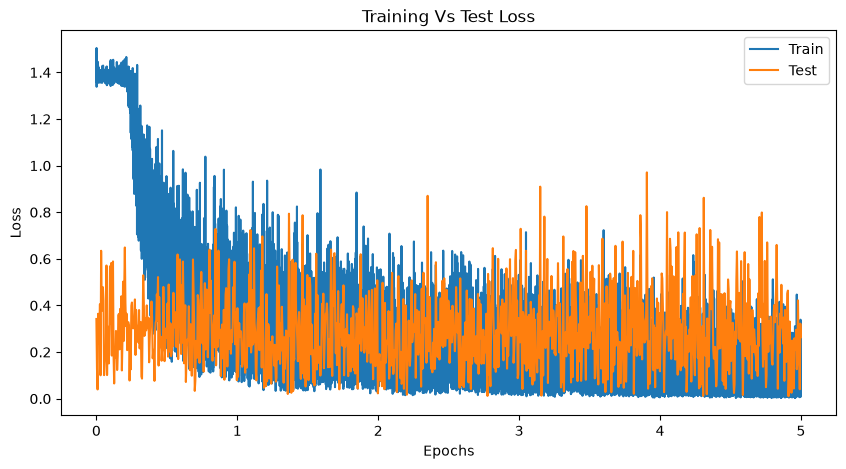

In [31]:
import numpy as np
plt.figure(figsize=(10, 5))
plt.plot(np.linspace(0, nepochs, len(train_loss_log)), train_loss_log)
plt.plot(np.linspace(0, nepochs, len(test_loss_log)), test_loss_log)

plt.legend(["Train", "Test"])
plt.title("Training Vs Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

Text(0, 0.5, 'Accuracy')

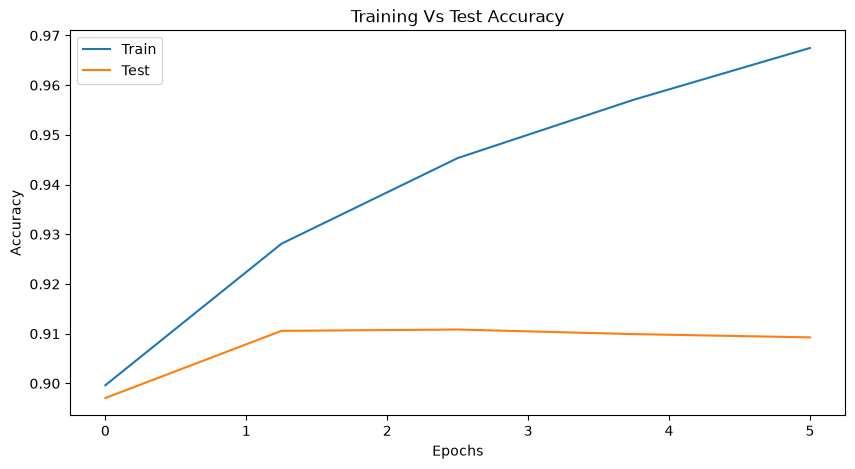

In [33]:
plt.figure(figsize=(10, 5))
plt.plot(np.linspace(0, nepochs, len(train_acc_log)), train_acc_log)
plt.plot(np.linspace(0, nepochs, len(test_acc_log)), test_acc_log)

plt.legend(["Train", "Test"])
plt.title("Training Vs Test Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

In [34]:
print(f'Max test accuracy is {np.max(test_acc_log)}')

Max test accuracy is 0.9108338356018066


- The model seems to be overfitting out train data, this could be because of huge vocabulary that we had.

In [44]:
# inference

seq = 'Space is full of Balck holes and stars'
print('Input seq: ',seq)

classifier.eval()
tokenized = text_transform(tokenizer(seq))
prediction = classifier(tokenized.unsqueeze(0))  #model expects the shape [batch_size, seq_length]

print('The predicted label: ',LABELS[prediction.argmax(1).item() + 1])

Input seq:  Space is full of Balck holes and stars
The predicted label:  Sci/Tech
